## LangChain / LangGraph 에이전트 데이터 관리 실습

**학습 목표:** 에이전트의 입력/출력, 공유 State, 메시지, Reducer, Runtime Context, Checkpointer(단기기억), Store(장기기억), 노드 이동과 데이터 전달, Tool, Agent 구조를 **직접 실행하면서** 이해합니다.

- 환경: **Python 3.12**, LangChain 1.x / LangGraph 1.x
- **1~10장:** 대부분 LLM/API 키 없이 실행 가능
- **11장:** OpenAI API 키가 있을 때 `gpt-4o-mini`로 실제 에이전트 실행
- 예제별로 독립적인 그래프를 생성하므로 위에서부터 실행하기 쉽습니다.

> **`State`는 실행 중의 공유 데이터 구조, `Checkpointer`는 스레드별 State 이력 저장, `Store`는 세션을 넘어 공유할 정보, `Runtime Context`는 실행마다 주입되는 읽기 전용 설정입니다. State와 Context는 그 자체로 DB가 아닙니다.**

> **한눈에 보기**
> - 에이전트 데이터의 통로 구분: State(공유 작업 공간) · Reducer(병합 규칙) · MessagesState · 입출력 스키마
> - Runtime Context(실행마다 주입, 저장 안 함) · Checkpointer(thread별 State 스냅샷 = 단기 기억) · Store(대화방을 넘는 장기 기억)
> - State·Context는 DB가 아니다. Store에 넣어도 LLM이 자동으로 읽지 않으니 노드·도구가 꺼내서 넘긴다
> - Command·Send 복습, 실제 `create_agent`(system_prompt는 State에 저장 안 됨), `ToolRuntime` + `Command`로 도구가 State 갱신
> - 정리 문서: [에이전트데이터관리.md](에이전트데이터관리.md) · 강의 슬라이드 이미지 포함(설명 예시 속 사람 이름만 가림), 📝 정리 셀은 직접 정리

## 0. 설치 및 공통 준비

아래 설치 셀은 환경에서 **한 번만** 실행합니다. 설치 후 import 오류가 있으면 커널을 재시작하세요. LangGraph 기능을 위주로 실습하므로 `langgraph`도 직접 설치합니다.

> 본 노트북의 메모리 저장소는 RAM 기반입니다. **커널 종료 후에도 남아 있는 저장소가 아닙니다.** 마지막 장에서 DB 저장소 선택 방법을 안내합니다.

In [1]:
#%pip install -q -U "langchain>=1,<2" "langgraph>=1,<2" "langchain-openai>=1,<2"

In [2]:
import os
from typing import TypedDict, Annotated
from pprint import pprint
from langgraph.graph import StateGraph, START, END, MessagesState
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.store.memory import InMemoryStore
from langgraph.runtime import Runtime
from langchain_core.messages import HumanMessage, AIMessage

print("공통 라이브러리 준비 완료")

공통 라이브러리 준비 완료


### 1. State : 노드 간 데이터를 공유하는 작업 공간

각 노드는 `state` 딕셔너리를 읽고, **변경할 필드만 담은 딕셔너리**를 반환합니다. 다음 노드는 갱신된 State를 읽습니다. `add_edge()`는 실행 순서를 연결하지 데이터를 별도로 복사해서 전달하는 API는 아닙니다.

In [3]:
class State1(TypedDict):
    question: str
    category: str
    answer: str

def classify(state: State1):
    print("[A] 질문:", state["question"])
    return {"category": "AI"}

def write_answer(state: State1):
    print("[B] A가 기록한 분류:", state["category"])
    return {"answer": f"{state['category']} 주제: {state['question']}에 대한 답변"}

b = StateGraph(State1)
b.add_node("classify", classify)
b.add_node("write_answer", write_answer)

b.add_edge(START, "classify")
b.add_edge("classify", "write_answer")
b.add_edge("write_answer", END)
graph1 = b.compile()

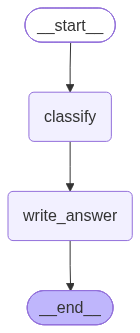

In [4]:
display(graph1)

In [5]:
result1 = graph1.invoke({"question": "LangGraph란?", "category": "", "answer": ""})
print("[ 에이전트 실행 결과 ]")
pprint(result1)

[A] 질문: LangGraph란?
[B] A가 기록한 분류: AI
[ 에이전트 실행 결과 ]
{'answer': 'AI 주제: LangGraph란?에 대한 답변',
 'category': 'AI',
 'question': 'LangGraph란?'}


**📝 정리** — `classify`는 `category`만 반환했는데 `question`이 남아 있고, 다음 노드가 `category`를 읽었다. 데이터는 엣지가 아니라 공유 State로 전달된다.

A는 `category`만 반환했지만 `question`은 그대로 유지됩니다. **`State`는 그래프 안의 모든 노드들이 데이터를 읽고 수정하며 공유할 수 있도록 만들어 주는 '중앙 집중식 공유 메모리**입니다.

### 2. Reducer : State 업데이트 병합 

- LangGraph의 State는 노드가 새로운 값을 반환하면 기존 값을 무조건 덮어쓰기(Overwrite)합니다.

- **Annotated[list[str], operator.add]** 처럼 Annotated를 사용하고 뒤에 함수(여기서는 operator.add)를 지정해 주면 

  - 노드가 새로운 리스트(["A 완료"])를 반환했을 때, 기존에 있던 리스트와 새 리스트를 파이썬의 덧셈 연산(+, 즉 이어 붙이기)을 이용해 안전하게 누적(Reduce)시킵니다.

- 여러 노드가 차례대로 실행되면서 데이터를 덮어쓰지 않고 차곡차곡 모아나가야 할 때(로그, 메시지 히스토리 등) 이 리듀서 개념이 핵심적으로 사용됩니다

In [6]:
import operator

class State2(TypedDict):
    steps: Annotated[list[str], operator.add]  # 리스트 이어 붙이기
    status: str                                 # 마지막 값으로 갱신

def step_a(state: State2):
    return {"steps": ["A 완료"], "status": "A"}

def step_b(state: State2):
    return {"steps": ["B 완료"], "status": "B"}

b = StateGraph(State2)
b.add_node("A", step_a)
b.add_node("B", step_b)

b.add_edge(START, "A")
b.add_edge("A", "B")
b.add_edge("B", END)
graph2 = b.compile()

In [7]:
pprint(graph2.invoke({"steps": [], "status": "시작"}))

{'status': 'B', 'steps': ['A 완료', 'B 완료']}


**📝 정리** — 리듀서가 있는 `steps`는 쌓이고, 없는 `status`는 마지막 값 'B'만 남았다.

In [8]:
for event in graph2.stream({"steps": [], "status": "시작"}, stream_mode="updates"): # 각 노드가 실행될 때마다 어떤 데이터가 갱신되었는지 실시간으로 출력
    print(event)

{'A': {'steps': ['A 완료'], 'status': 'A'}}
{'B': {'steps': ['B 완료'], 'status': 'B'}}


### 3. MessagesState — Human / AI / Tool 메시지를 관리

- 메시지 기록(Chat History) 관리를 위해 미리 정의해 둔 빌트인 State 클래스 

- 대화 전용 공유 메모리: 매번 대화형 에이전트를 만들 때마다 TypedDict를 일일이 선언하고 리듀서를 설정하는 번거로움을 줄여줍니다.

- 스마트한 메시지 누적 (add_messages 리듀서 탑재): **내부적으로 messages라는 필드** 를 가지며, 단순히 리스트를 이어 붙이는 것을 넘어 메시지의 ID를 기반으로 기존 메시지를 업데이트하거나 대체할 수 있는 지능형 리듀서가 기본 적용되어 있습니다.

In [9]:
class State3(MessagesState):
    summary: str

def echo_node(state: State3):
    last = state["messages"][-1].content
    return {"messages": [AIMessage(content=f"질문을 받았습니다: {last}")], "summary": "응답 완료~~~~"}

b = StateGraph(State3)
b.add_node("echo", echo_node)

b.add_edge(START, "echo")
b.add_edge("echo", END)
graph3 = b.compile()

In [10]:

result3 = graph3.invoke({"messages": [HumanMessage(content="안녕하세요")], "summary": ""})
for m in result3["messages"]:
    print(type(m).__name__, ":", m.content)
print("별도의 State 값:", result3["summary"])

HumanMessage : 안녕하세요
AIMessage : 질문을 받았습니다: 안녕하세요
별도의 State 값: 응답 완료~~~~


In [11]:
for event in graph3.stream({"messages": [HumanMessage(content="안녕하세요")], "summary": ""}, stream_mode="debug"): 
    print(event)

{'step': 1, 'timestamp': '2026-10-30T01:06:13.930605+00:00', 'type': 'task', 'payload': {'id': 'b75a440a-aa61-1a78-e017-99bfbc707112', 'name': 'echo', 'input': {'messages': [HumanMessage(content='안녕하세요', additional_kwargs={}, response_metadata={}, id='1f8541a4-c3ab-4434-bc13-76b969b36bee')], 'summary': ''}, 'triggers': ('branch:to:echo',)}}
{'step': 1, 'timestamp': '2026-10-30T01:06:13.931604+00:00', 'type': 'task_result', 'payload': {'id': 'b75a440a-aa61-1a78-e017-99bfbc707112', 'name': 'echo', 'error': None, 'result': {'messages': [AIMessage(content='질문을 받았습니다: 안녕하세요', additional_kwargs={}, response_metadata={}, id='c2765c52-f86f-4def-a4cf-6a44653ff51e', tool_calls=[], invalid_tool_calls=[])], 'summary': '응답 완료~~~~'}, 'interrupts': []}}


**📝 정리** — `debug` 모드는 노드 실행 전(`task`)과 후(`task_result`) 이벤트를 타임스탬프와 함께 모두 보여 준다.

### 4. Input / Output Schema : 외부 입출력과 내부 State 분리

- LangGraph에서 외부 입출력(Input/Output)과 내부 State를 분리하는 개념은, 복잡한 에이전트와 워크플로우를 설계할 때 공개 API 인터페이스(Contract)와 내부 구현용 데이터(Internal Scratchpad)를 깔끔하게 격리하는 핵심 아키텍처 패턴입니다.

- LangGraph에서 아무 설정 없이 StateGraph(MyState)를 쓰면, 사용자가 그래프를 호출할 때 넣는 입력값, 노드들이 내부에서 주고받는 중간 데이터, 그리고 최종 사용자가 받는 출력값이 전부 똑같은 하나의 거대한 State를 공유하게 됩니다.

- LangGraph는 이를 해결하기 위해 그래프 컴파일 시점에 입출력 스키마를 별도로 지정할 수 있도록 지원합니다.   
  - Input Schema (입력 스키마) : 사용자가 그래프를 실행(invoke())할 때 반드시 제공해야 하는 최소한의 입력 데이터 구조 정의   
  - Internal / Overall State (내부 전체 스키마)  : 그래프 내부의 모든 노드들이 실행되면서 읽고 쓰는 전체 데이터 구조. 입력값뿐만 아니라 중간 연산 결과, 로그 등이 모두 포함   
  - Output Schema (출력 스키마)  : 그래프 실행이 모두 끝난 후, 외부 사용자에게 최종적으로 반환할 결과 데이터 구조를 정의. 내부의 지저분한 중간 데이터는 여기서 필터링되어 가려짐   

`사용자는 깔끔하게 질문만 던지고(Input) 결과만 받아가며(Output), 그래프 내부에서는 노드들끼리 온갖 복잡한 중간 데이터(Internal State)를 자유롭게 공유하며 일할 수 있도록 만들어주는 완벽한 캡슐화 장치입니다.`

In [12]:
class Input4(TypedDict):
    question: str

class Output4(TypedDict):
    answer: str

class State4(TypedDict):
    question: str
    search_result: str
    answer: str

def search4(state: State4):
    return {"search_result": "State를 노드가 공유합니다."}

def answer4(state: State4):
    return {"answer": f"{state['question']} → {state['search_result']}"}

b = StateGraph(State4, input_schema=Input4, output_schema=Output4)
b.add_node("search", search4)
b.add_node("answer", answer4)

b.add_edge(START, "search")
b.add_edge("search", "answer")
b.add_edge("answer", END)
graph4 = b.compile()

In [13]:
print(graph4.invoke({"question": "State란?"}))  # answer만 반환

{'answer': 'State란? → State를 노드가 공유합니다.'}


**📝 정리** — 출력 스키마 덕분에 내부 필드 `search_result` 없이 `answer`만 반환됐다.

### 5. Runtime Context — State에 저장하지 않는 실행 환경 정보

`Runtime Context(실행 환경 정보, 주로 config 또는 RunnableConfig로 지칭)는 그래프의 State(상태)에는 저장하지 않지만, 그래프가 실행되는 동안(Runtime) 노드들이 참조할 수 있도록 외부에서 주입해 주는 부가적인 실행 환경 정보를 뜻합니다.`

- State (상태) : 노드들이 거쳐 가며 값을 읽고 쓰고 누적하는 데이터, Checkpointer에 의해 데이터베이스나 메모리에 영구 저장(Persistence)되며, 대화 기록이나 작업 결과물처럼 계속 유지되어야 하는 데이터들이 담깁니다.

- Runtime Context (실행 환경 정보) : 데이터베이스에 저장할 필요가 없고, 오직 이번 한 번의 실행(Invocation) 동안에만 유효한 설정이나 환경 값,
상태가 변하지 않는 읽기 전용(Read-only) 성격의 메타데이터입니다.

In [14]:
class Context5(TypedDict):
    user_id: str
    language: str

class State5(TypedDict):
    question: str
    answer: str

def answer5(state: State5, runtime: Runtime[Context5]):
    ctx = runtime.context
    return {"answer": f"[{ctx['user_id']}] {ctx['language']}로 답변: {state['question']}"}

b = StateGraph(State5, context_schema=Context5)
b.add_node("answer", answer5)

b.add_edge(START, "answer")
b.add_edge("answer", END)
graph5 = b.compile()

In [15]:
pprint(graph5.invoke({"question": "안녕하세요", "answer": ""},
                    context={"user_id": "u01", "language": "한국어"}))

{'answer': '[u01] 한국어로 답변: 안녕하세요', 'question': '안녕하세요'}


In [16]:
# [ 예제 추가 ]

from langchain_core.runnables import RunnableConfig

class State(TypedDict):
    question: str
    answer: str

# 1. 노드 함수에서 config 인자 받기
def model_node(state: State, config: RunnableConfig):
    # Runtime Context에서configurable 정보 꺼내기
    configurable = config.get("configurable", {})
    user_id = configurable.get("user_id", "guest")
    model_version = configurable.get("model_version", "v1")
    
    print(f"현재 사용자: {user_id}, 사용하는 모델 버전: {model_version}")
    
    return {"answer": f"질문 '{state['question']}'에 대한 답변입니다."}

workflow = StateGraph(State)
workflow.add_node("model", model_node)

workflow.add_edge(START, "model")
workflow.add_edge("model", END)
app = workflow.compile()

In [17]:
# 2. invoke 할 때 config로 Runtime Context 주입하기
result = app.invoke(
    {"question": "안녕?"}, 
    config={
        "configurable": {
            "user_id": "unico",
            "model_version": "v2.0"
        }
    }
)

현재 사용자: unico, 사용하는 모델 버전: v2.0


**📝 정리** — `config["configurable"]`로 넘긴 값을 노드의 `config: RunnableConfig` 인자로 읽는 방식. 지금은 `context_schema` + `Runtime`이 권장 방식이다.

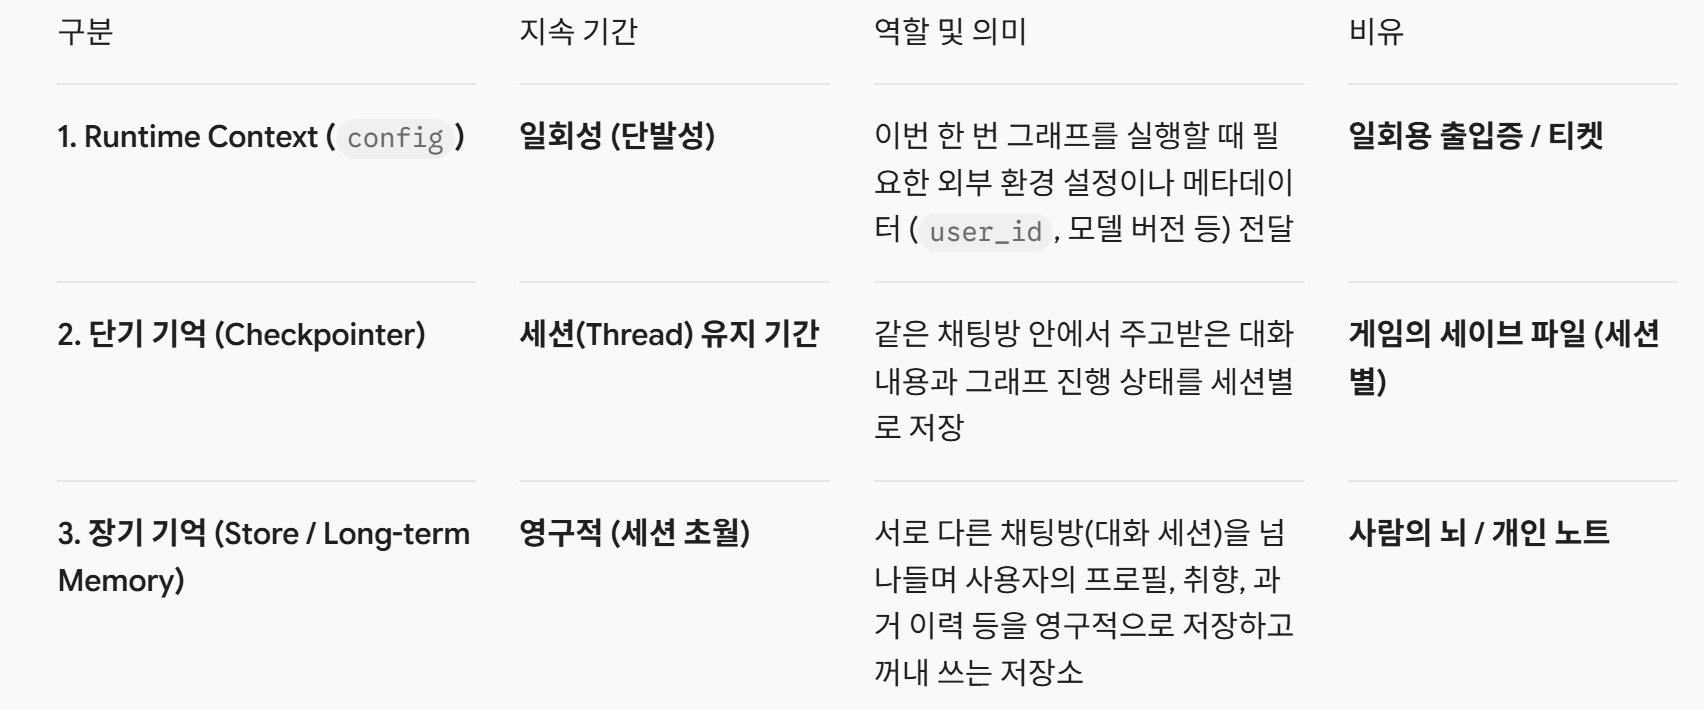

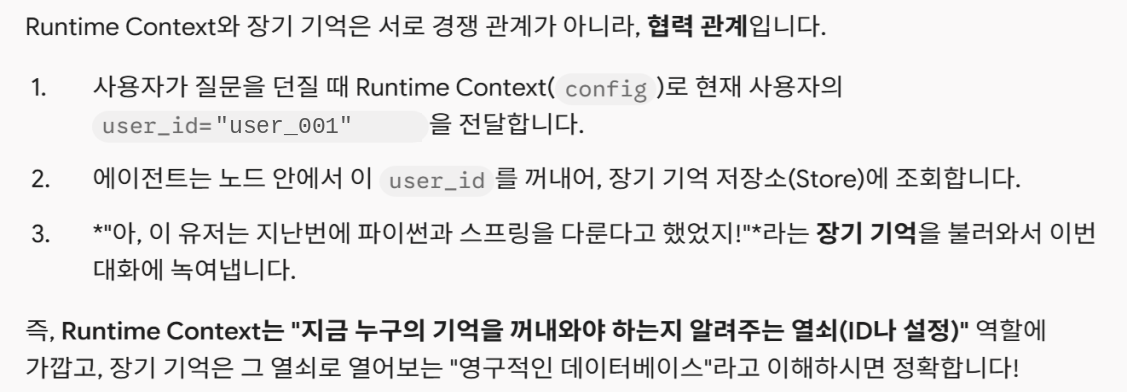

### 6. Edge / Conditional Edge / Command — 노드 실행 흐름

- LangGraph(랭체인 생태계)에서 도입된 Command 객체는 노드 안에서 "데이터(State) 업데이트"와 "다음에 어떤 노드로 갈 것인지(Routing)"를 한 번에 처리할 수 있게 만들어 주는 강력한 만능 리턴 객체입니다.

- Command 객체는 주로 다음 두 가지 핵심 인자를 담아 반환합니다.\
  `update: State에 반영할 데이터 딕셔너리 (기존에 노드가 딕셔너리를 리턴하던 역할)`\
  `goto: 다음에 실행할 노드의 이름(문자열) 또는 특수 제어 명령`

- Command 객체가 주로 쓰이는 시나리오
  - 동적 라우팅 (Dynamic Routing) : 복잡한 조건부 엣지 함수를 따로 빼서 정의할 필요 없이, **노드 내부의 비즈니스 로직 안에서 자연스럽게 다음 경로를 이동할 때** 사용합니다.

  - 멀티 에이전트 핸드오프 (Handoff) : 에이전트 A가 일을 하다가 "이건 재무 담당 에이전트에게 넘겨야겠어"라고 판단하면, **Command(update=..., goto="finance_agent")** 를 통해 권한을 즉시 다른 에이전트로 넘길 수 있습니다.

  - Human-in-the-Loop (인간 승인 제어) : 작업 중간에 **Command와 interrupt()** 를 결합하여 사용자의 승인을 기다릴 수도 있습니다.

---
`add_edge(A, B)` : A 다음 B를 실행, `add_conditional_edges()` : 현재 State에 따라 경로 선택\
`Command(update=..., goto=...)` : **State 업데이트와 다음 노드 선택을 한 번에** 처리

Command 객체는 `노드가 자신의 작업 결과를 State에 반영하는 것과 동시에, 다음에 어느 노드로 이동해야 할지 직접 지휘(Routing)할 수 있게 해 주는 스마트한 내비게이션 도구`입니다.

In [18]:
from typing import Literal
from langgraph.types import Command

class State6(TypedDict):
    score: int
    route: str
    answer: str

def router6(state: State6) -> Command[Literal["pass_node", "retry_node"]]:
    route = "pass_node" if state["score"] >= 60 else "retry_node"
    return Command(update={"route": route}, goto=route)

def pass6(state: State6):
    return {"answer": "합격"}

def retry6(state: State6):
    return {"answer": "재학습 필요"}

b = StateGraph(State6)
b.add_node("router", router6)
b.add_node("pass_node", pass6)
b.add_node("retry_node", retry6)

b.add_edge(START, "router")
b.add_edge("pass_node", END)
b.add_edge("retry_node", END)
graph6 = b.compile()

In [19]:
for score in [85, 40]:
    print(score, graph6.invoke({"score": score, "route": "", "answer": ""}))

85 {'score': 85, 'route': 'pass_node', 'answer': '합격'}
40 {'score': 40, 'route': 'retry_node', 'answer': '재학습 필요'}


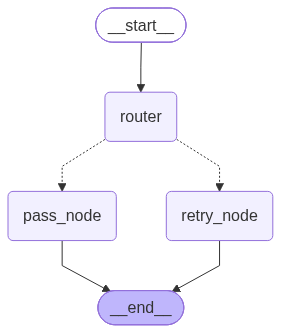

In [20]:
graph6

### 7. Send — 다른 입력을 병렬 작업 노드에 전달 (Map-Reduce)

- Send 객체는 하나의 노드에서 **서로 다른 입력값**을 만들어, 여러 노드(또는 동일한 노드의 여러 인스턴스)로 **동시에 병렬 작업(Fan-out)** 을 지시할 수 있게 해 주는 **동적 분기(Routing) 도구**입니다.

- 거대한 문서 리스트(["문서1", "문서2", "문서3"])가 있을 때, 각 문서마다 서로 다른 내용을 추출하거나 요약하는 작업을 동시에(병렬로) 시키고 싶다면 Send 객체를 써서 각기 다른 입력 데이터를 개별 노드에 쪼개어 보낼 수 있습니다.

- Map-Reduce (Fan-out / Fan-in) 동작 흐름
  Send 객체를 활용한 Map-Reduce 패턴은 전형적으로 3단계로 이루어집니다.

  - Map (분배 - Fan-out) :\
    입력받은 데이터를 여러 조각으로 쪼개고, 각 조각에 맞는 대상 노드와 데이터를 담아 여러 개의 Send 객체 리스트를 반환

  - Parallel Processing (병렬 실행) :\
    LangGraph가 리스트에 담긴 Send 객체들을 감지하고, 지정된 노드들을 동시에 병렬로 실행(각 노드는 자신만의 독립된 입력을 처리)

  - Reduce (종합 - Fan-in) :\
    병렬 노드들이 끝난 결과는 State의 리듀서(예: operator.add)를 통해 자동으로 하나의 리스트로 합쳐집니다. 이후 최종 취합 노드가 이 결과를 받아 최종 요약 등을 수행

- `Send("worker", {"item": ...})` 객체는 각각의 작업에 **서로 다른 State 입력**을 전달합니다. 

`Send 객체는 "하나의 데이터를 여러 조각으로 쪼개어(Map), 서로 다른 입력값을 가진 여러 노드를 동시에 병렬 가동(Fan-out)시킨 뒤 결과를 안전하게 취합(Reduce)할 수 있게 해 주는 Map-Reduce의 핵심 엔진" 입니다.`

In [21]:
from langgraph.types import Send

class BatchState(TypedDict):
    items: list[int]
    results: Annotated[list[int], operator.add]

class WorkerState(TypedDict):
    item: int

def dispatch(state: BatchState):
    return [Send("worker", {"item": x}) for x in state["items"]]

def worker(state: WorkerState):
    return {"results": [state["item"] ** 2]}

b = StateGraph(BatchState)
b.add_node("worker", worker)
b.add_conditional_edges(START, dispatch, ["worker"])

b.add_edge("worker", END)
graph7 = b.compile()

In [22]:
print(graph7.invoke({"items": [2, 3, 4], "results": []}))

{'items': [2, 3, 4], 'results': [4, 9, 16]}


**📝 정리** — Send로 보낸 워커는 자기 전용 입력(`{"item": x}`)만 받고, 결과는 `operator.add`로 `[4, 9, 16]`에 모였다.

In [23]:
# [ 예제 추가 ]
from typing import Annotated, TypedDict
import operator
from langgraph.graph import StateGraph, START, END
from langgraph.types import Send

# 1. 전체 그래프가 관리할 State (결과는 리듀서로 누적)
class OverallState(TypedDict):
    numbers: list[int]                      # 입력받을 숫자들 (예: [1, 2, 3])
    results: Annotated[list[int], operator.add] # 결과들이 합쳐질 공간

# 2. 개별 워커(일꾼)가 처리할 때 사용할 전용 State
class WorkerState(TypedDict):
    number: int  # 한 번에 하나씩 받을 숫자

# 3. 개별 워커 노드: 숫자를 받아서 10을 곱한 뒤 리스트 형태로 반환
def multiply_by_ten(state: WorkerState):
    num = state["number"]
    calculated = num * 10
    print(f"⚡ [워커 실행] 입력받은 숫자: {num} -> 계산 결과: {calculated}")
    return {"results": [calculated]}  # 리듀서에 의해 기존 results에 누적됨

# 4. 그래프 빌드
workflow = StateGraph(OverallState)

# 워커 노드 등록
workflow.add_node("multiply_node", multiply_by_ten)

# 5. 핵심: START에서 리스트의 각 아이템을 Send로 쪼개어 동시 파견하는 라우터 함수
def dispatch_jobs(state: OverallState):
    # numbers에 있는 숫자들을 하나씩 꺼내어 각각 Send("노드이름", {"number": 숫자}) 생성
    return [Send("multiply_node", {"number": n}) for n in state["numbers"]]

# 조건부 엣지를 통해 START에서 여러 개의 Send로 병렬 분기 (Fan-out)
workflow.add_conditional_edges(
    START, 
    dispatch_jobs, 
    ["multiply_node"]
)

# 병렬 작업이 끝난 노드는 END로 연결 (Fan-in 취합)
workflow.add_edge("multiply_node", END)

app = workflow.compile()

# --- 실행 테스트 ---
initial_state = {
    "numbers": [1, 2, 3, 4, 5],
    "results": []
}

final_result = app.invoke(initial_state)
print("\n🎯 최종 결과 출력:")
print(final_result)

⚡ [워커 실행] 입력받은 숫자: 1 -> 계산 결과: 10
⚡ [워커 실행] 입력받은 숫자: 2 -> 계산 결과: 20
⚡ [워커 실행] 입력받은 숫자: 3 -> 계산 결과: 30
⚡ [워커 실행] 입력받은 숫자: 4 -> 계산 결과: 40
⚡ [워커 실행] 입력받은 숫자: 5 -> 계산 결과: 50

🎯 최종 결과 출력:
{'numbers': [1, 2, 3, 4, 5], 'results': [10, 20, 30, 40, 50]}


- 사용자가 [1, 2, 3, 4, 5]라는 숫자를 넣고 실행(invoke)합니다.
- dispatch_jobs 함수가 실행되면서 Send 객체 5개가 생성됩니다.

  > Send("multiply_node", {"number": 1})\
  > Send("multiply_node", {"number": 2})\
  > ...\
  > Send("multiply_node", {"number": 5})

- LangGraph 엔진은 이 5개의 Send를 감지하고, multiply_node를 5개로 복제하듯 동시에(병렬로) 실행합니다.
- 각 노드가 계산한 결과(10, 20, 30, 40, 50)는 State의 리듀서(operator.add) 덕분에 충돌 없이 results 리스트에 합쳐집니다.

### 8. Checkpointer — thread_id별 단기기억과 실행 이력

- **Checkpointer는 대화 메시지만 저장하는 것이 아니라 State의 스냅샷을 기록합니다.**
- 동일한 `thread_id`를 사용하면 이전 실행의 State에서 이어질 수 있습니다. 
- 새 메시지를 누적하고 `get_state()` / `get_state_history()`로 확인합니다.

⚠️ InMemorySaver는 커널을 종료하면 사라집니다.

In [24]:
class MemoryState(MessagesState):
    count: int

def remember8(state: MemoryState):
    old = state.get("count", 0)
    text = state["messages"][-1].content
    return {
        "count": old + 1,
        "messages": [AIMessage(content=f"{old + 1}번째 입력을 받았습니다: {text}")]
    }

b = StateGraph(MemoryState)
b.add_node("remember", remember8)

b.add_edge(START, "remember")
b.add_edge("remember", END)
checkpointer8 = InMemorySaver()
graph8 = b.compile(checkpointer=checkpointer8)

In [25]:
config_a = {"configurable": {"thread_id": "session-A"}}
config_b = {"configurable": {"thread_id": "session-B"}}

graph8.invoke({"messages": [HumanMessage(content="첫 질문")]}, config=config_a)
graph8.invoke({"messages": [HumanMessage(content="두 번째 질문")]}, config=config_a)
graph8.invoke({"messages": [HumanMessage(content="다른 사람 질문")]}, config=config_b)

print("A 횟수:", graph8.get_state(config_a).values["count"])
print("B 횟수:", graph8.get_state(config_b).values["count"])
print("A 메시지 유형:", [type(m).__name__ for m in graph8.get_state(config_a).values["messages"]])
print("B 메시지 유형:", [type(m).__name__ for m in graph8.get_state(config_b).values["messages"]])
print("A checkpoint 개수:", len(list(graph8.get_state_history(config_a))))
print("B checkpoint 개수:", len(list(graph8.get_state_history(config_b))))

A 횟수: 2
B 횟수: 1
A 메시지 유형: ['HumanMessage', 'AIMessage', 'HumanMessage', 'AIMessage']
B 메시지 유형: ['HumanMessage', 'AIMessage']
A checkpoint 개수: 6
B checkpoint 개수: 3


**📝 정리** — A는 2번, B는 1번 호출 → 체크포인트 6개 / 3개. 메시지뿐 아니라 `count`까지 State 전체가 thread별로 저장된다.

In [26]:
print("A checkpoint 내용:", list(graph8.get_state_history(config_a)))
print("-"*30)
print("B checkpoint 내용:", list(graph8.get_state_history(config_b)))

A checkpoint 내용: [StateSnapshot(values={'messages': [HumanMessage(content='첫 질문', additional_kwargs={}, response_metadata={}, id='efb1b92b-07d3-4f26-9481-f9ee35a02fda'), AIMessage(content='1번째 입력을 받았습니다: 첫 질문', additional_kwargs={}, response_metadata={}, id='cc25f654-dbae-4269-94a5-0057933ce441', tool_calls=[], invalid_tool_calls=[]), HumanMessage(content='두 번째 질문', additional_kwargs={}, response_metadata={}, id='1e166a0f-5a18-41ff-8398-f0f7eb8d18d3'), AIMessage(content='2번째 입력을 받았습니다: 두 번째 질문', additional_kwargs={}, response_metadata={}, id='66c64b43-635e-4673-9c02-6430caeb8eee', tool_calls=[], invalid_tool_calls=[])], 'count': 2}, next=(), config={'configurable': {'thread_id': 'session-A', 'checkpoint_ns': '', 'checkpoint_id': '1f1d3fe1-b323-6689-8004-dce7ab843db2'}}, metadata={'source': 'loop', 'step': 4, 'parents': {}}, created_at='2026-10-30T01:06:15.662554+00:00', parent_config={'configurable': {'thread_id': 'session-A', 'checkpoint_ns': '', 'checkpoint_id': '1f1d3fe1-b320-6f7c-8

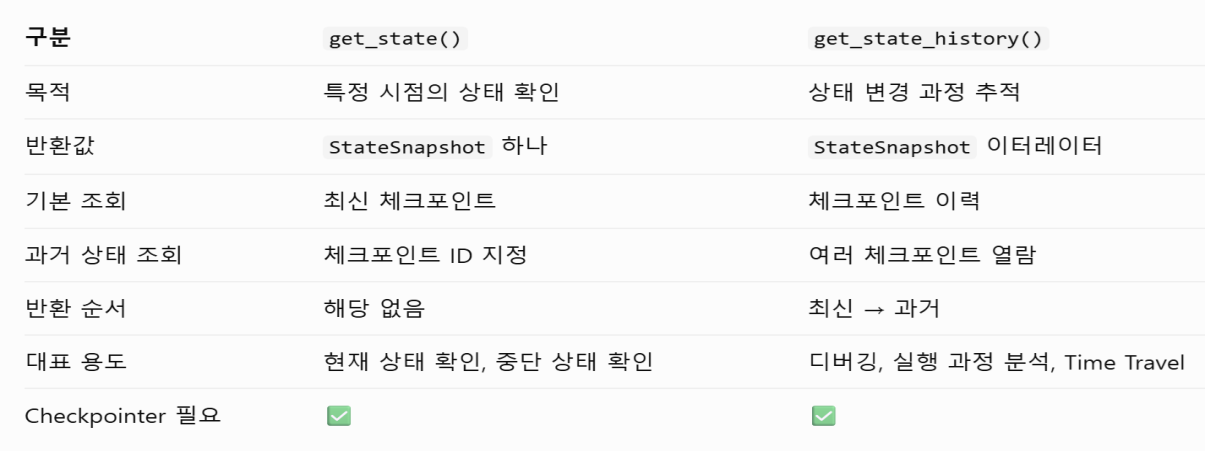

## 9. Store : 여러 대화에 걸쳐 공유되는 장기기억

- Store는 `(namespace, key) → JSON 값` 형태로 사용자 프로필 등을 관리합니다. 
- `thread_id`와 관계없이 동일한 Store에 접근하면 데이터를 공유할 수 있습니다.
- Store에 데이터를 저장한다고 LLM이 자동으로 장기기억을 읽는 것은 아닙니다. 에이전트 코드가 적절한 시점에 `get`/`search`한 결과를 모델에 제공해야 합니다.

In [27]:
store9 = InMemoryStore()
namespace = ("users", "u01")
store9.put(namespace, "profile", {"preferred_language": "Python", "level": "beginner"})
print("저장된 장기기억:", store9.get(namespace, "profile").value)
print("namespace 내 데이터 수:", len(store9.search(namespace)))

저장된 장기기억: {'preferred_language': 'Python', 'level': 'beginner'}
namespace 내 데이터 수: 1


### 9-1. Store + Runtime Context + State 연동

- 노드 A는 Context에서 사용자 ID를 읽고 Store에서 사용자 정보를 가져와 State의 `preference`에 기록합니다. 
- 노드 B는 해당 값을 읽습니다.

` 이 예제는 세 가지 통로의 차이를 명확하게 보여줍니다.`

In [28]:
store9 = InMemoryStore()

class State9(TypedDict):
    question: str
    preference: str
    answer: str

class Context9(TypedDict):
    user_id: str

def load_profile9(state: State9, runtime: Runtime[Context9]):
    uid = runtime.context["user_id"]
    item = runtime.store.get(("users", uid), "profile")
    language = item.value["preferred_language"] if item else "미설정"
    return {"preference": language}

def use_profile9(state: State9):
    return {"answer": f"{state['preference']} 예제로 '{state['question']}'을 설명할게요."}

b = StateGraph(State9, context_schema=Context9)
b.add_node("load_profile", load_profile9)
b.add_node("use_profile", use_profile9)

b.add_edge(START, "load_profile")
b.add_edge("load_profile", "use_profile")
b.add_edge("use_profile", END)
graph9 = b.compile(store=store9, checkpointer=InMemorySaver())

In [29]:
print(graph9.invoke({"question": "리스트란?", "preference": "", "answer": ""},
                    config={"configurable": {"thread_id": "new-session"}},
                    context={"user_id": "u01"})["answer"])

미설정 예제로 '리스트란?'을 설명할게요.


**📝 정리** — "미설정"이 나온 이유: 앞 셀에서 u01 프로필을 넣은 `store9`를 이 셀에서 `InMemoryStore()`로 **새로 만들어** 빈 저장소가 됐다.

In [30]:
store9.put(
    ("users", "unico"),   # 네임스페이스 (구조화된 경로)
    "profile",                      # 데이터 키 이름
    {"preferred_language": "파이썬"}  # 저장할 데이터 (딕셔너리)
)

In [31]:
print(graph9.invoke({"question": "컴프리핸션이란?", "preference": "", "answer": ""},
                    config={"configurable": {"thread_id": "new-session"}},
                    context={"user_id": "unico"})["answer"])

파이썬 예제로 '컴프리핸션이란?'을 설명할게요.


**📝 정리** — unico 프로필을 넣은 뒤에는 Context(user_id) → Store(프로필) → State(preference) → 다음 노드 순으로 "파이썬"이 전달됐다.

### 10. Streaming — State에 저장하는 것과 실시간 전달은 다름

`stream(stream_mode="updates")`는 **각 노드가 만든 업데이트**를 순서대로 보여줍니다. 반면 Checkpointer는 실행 상태를 저장합니다. 둘을 혼동하지 마세요.

In [32]:
for event in graph1.stream({"question": "노드 업데이트를 보자", "category": "", "answer": ""},
                           stream_mode="updates"):
    pprint(event)

[A] 질문: 노드 업데이트를 보자
{'classify': {'category': 'AI'}}
[B] A가 기록한 분류: AI
{'write_answer': {'answer': 'AI 주제: 노드 업데이트를 보자에 대한 답변'}}


### 11. 실제 LangChain Agent — System Prompt / Messages / Tool / Checkpointer

 `OPENAI_API_KEY`를 환경변수로 설정해 사용합니다. 

- `system_prompt`: 에이전트 설정. (Checkpointer의 `messages` State에 직접 저장되지 않음)
- `messages`: Human/AI/Tool 메시지가 기록되는 필드
- `checkpointer`: 같은 `thread_id`로 이어지는 대화 보존
- `@tool`: 모델이 호출할 수 있는 Python 함수 정의

In [33]:
from langchain.agents import create_agent
from langchain.tools import tool

@tool
def double_number(value: int) -> int:
    """정수에 2를 곱합니다."""
    return value * 2

if not os.getenv("OPENAI_API_KEY"):
    print("OPENAI_API_KEY가 없어 실제 LLM 호출은 생략합니다.")
else:
    agent11 = create_agent(
        model="openai:gpt-4o-mini",
        tools=[double_number],
        system_prompt="당신은 간결한 한국어 수학 도우미입니다. 계산이 필요하면 도구를 사용하세요.",
        checkpointer=InMemorySaver(),
    )
    config11 = {"configurable": {"thread_id": "student-01"}}
    agent11.invoke({"messages": [{"role": "user", "content": "37의 두 배를 구해줘."}]}, config=config11)
    result11 = agent11.invoke({"messages": [{"role": "user", "content": "방금 계산한 내용이 뭐였지?"}]}, config=config11)
    for msg in result11["messages"]:
        print(type(msg).__name__, ":", str(msg.content)[:180])
    print("\n현재 저장된 State 필드:", list(agent11.get_state(config11).values))

HumanMessage : 37의 두 배를 구해줘.
AIMessage : 
ToolMessage : 74
AIMessage : 37의 두 배는 74입니다.
HumanMessage : 방금 계산한 내용이 뭐였지?
AIMessage : 방금 계산한 내용은 37의 두 배를 구한 것으로, 결과는 74입니다.

현재 저장된 State 필드: ['messages']


**📝 정리** — 같은 thread라 "방금 계산한 내용"을 기억했다. 저장된 State 필드는 `messages`뿐 — system_prompt는 저장되지 않는다.

### 12. ToolRuntime + Command : Tool이 공유 State를 갱신하는 방식 

- 일반 도구는 `ToolMessage`를 통해 결과를 모델에 전달합니다. 상태값까지 갱신해야 한다면 `ToolRuntime`과 `Command(update=...)`를 사용합니다.

- 아래는 **도구 함수의 동작 형태를 읽기 위한 예시**입니다. 

- 실제 에이전트에서 실행하려면 `search_result` 필드를 가진 커스텀 Agent State와 Tool 실행 노드가 필요합니다. \
여기서는 소스만 검토합니다.

In [34]:
from langchain.tools import ToolRuntime
from langchain_core.messages import ToolMessage
from langgraph.types import Command

# 예시 코드: 이 도구를 실제 에이전트에 등록하려면 커스텀 State가 필요합니다.
@tool
def save_result(query: str, runtime: ToolRuntime) -> Command:
    """검색 작업 결과를 Agent State에 기록합니다."""
    result = f"{query}: 검색 완료(예시)"
    return Command(update={
        "search_result": result,
        "messages": [ToolMessage(
            content="검색 결과를 State에 기록했습니다.",
            tool_call_id=runtime.tool_call_id,
        )],
    })

print("save_result Tool 정의 완료 (실행은 생략)")

save_result Tool 정의 완료 (실행은 생략)


### 13. 영속 저장소, RAG, Subgraph, Human-in-the-loop : 확장 개념

이 노트북은 학습 편의를 위해 메모리 기반 구현을 사용했습니다. 실서비스에서는 다음 기술을 추가 검토합니다.

| 기능 | 목적 | 대표 구성 |
|---|---|---|
| 영속 단기기억 | 프로세스 재시작 후 State 복원 | `PostgresSaver` (`langgraph-checkpoint-postgres`) |
| 영속 장기기억 | 사용자 프로필 저장 | `PostgresStore` (`langgraph-checkpoint-postgres`) |
| RAG | PDF/문서 지식 검색 | PGVector 등 Vector Store + Retriever |
| Subgraph | 하위 에이전트를 그래프에 결합 | `builder.add_node("subgraph", compiled_subgraph)` |
| Human-in-the-loop | 실행 중 일시중지·승인·재개 | `interrupt()`, `Command(resume=...)` |
| State 복구/분기 | 이전 체크포인트에서 재개·분기 | `get_state_history()`, checkpoint config |
| LLM 출력 형식 | JSON/Pydantic 결과 제어 | `response_format` / `with_structured_output()` |
| 모델 문맥 관리 | 오래된 메시지 잘라내기/요약 | trim / summarize middleware |
| 실행 추적 | 각 노드·도구 호출 확인 | LangSmith tracing |

<br>

> **추가 구분:** Vector Store는 주로 검색할 자료를 저장하는 공간이고, LangGraph Store는 에이전트의 기억·사용자 정보 등을 다루는 범용 Key-Value 저장소입니다. Store에 의미 검색용 인덱스를 추가할 수도 있습니다.

### 공식 참고 문서

- [LangGraph Graph API](https://docs.langchain.com/oss/python/langgraph/graph-api)
- [LangGraph Persistence](https://docs.langchain.com/oss/python/langgraph/persistence)
- [LangChain Short-term Memory](https://docs.langchain.com/oss/python/langchain/short-term-memory)
- [LangChain Long-term Memory](https://docs.langchain.com/oss/python/langchain/long-term-memory)
- [LangChain Tools](https://docs.langchain.com/oss/python/langchain/tools)

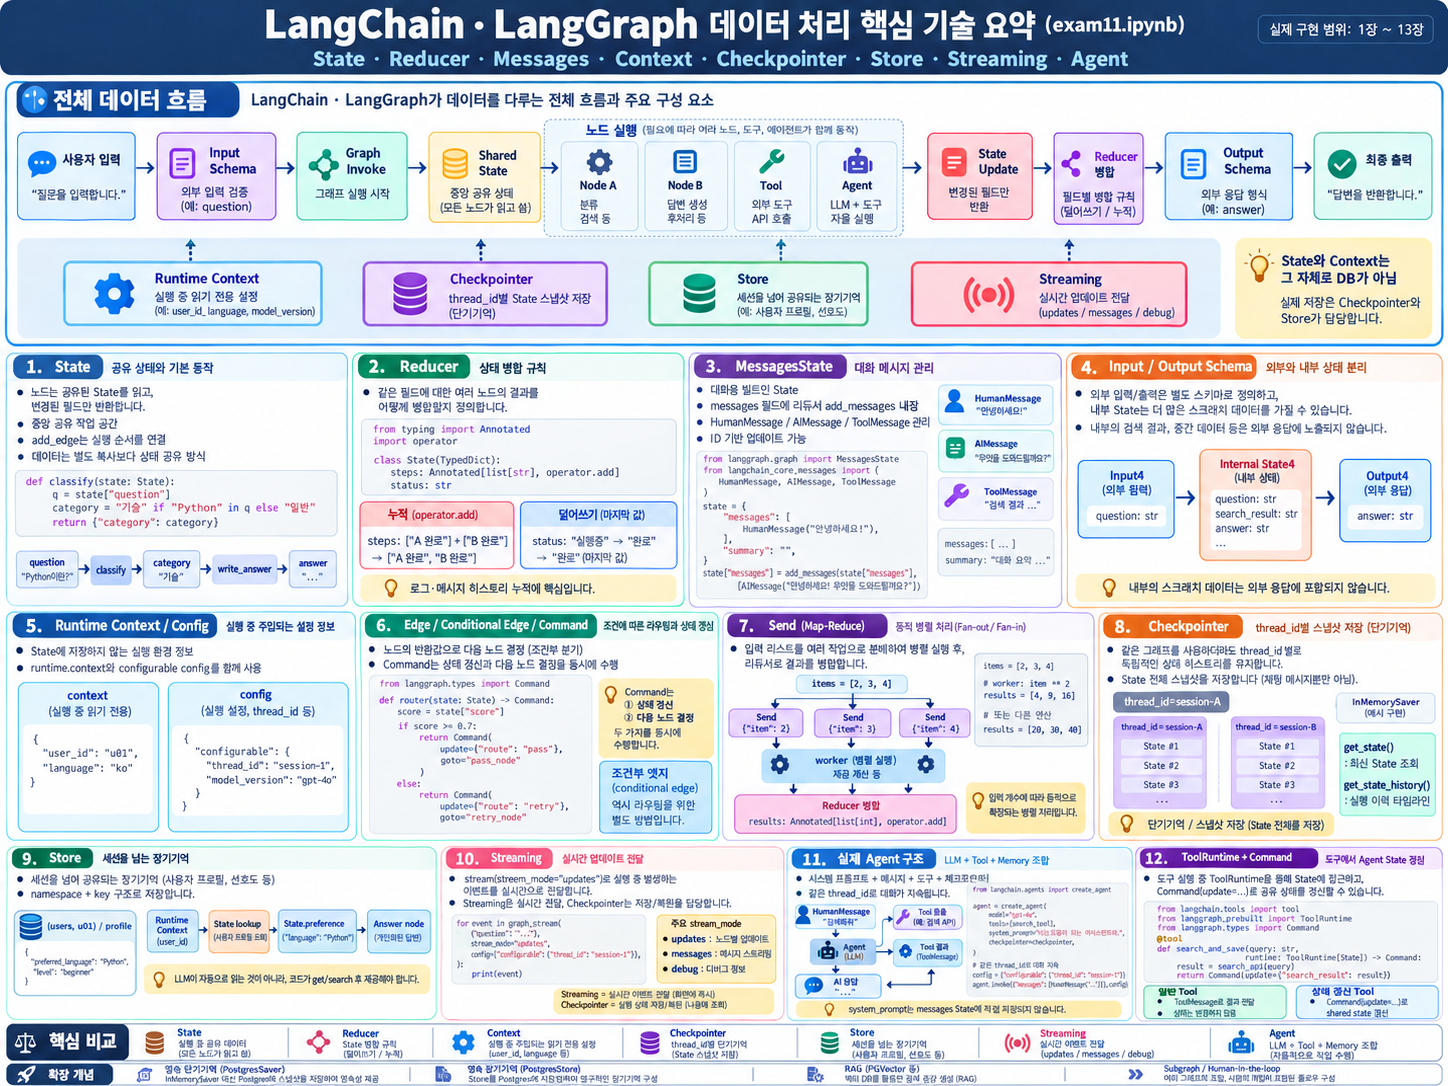

## 🔁 복습 질문

<details>
<summary>1. State와 Runtime Context 중 체크포인트에 저장되는 것은?</summary>

State. Context는 실행마다 새로 넣는 읽기 전용 설정이다.
</details>

<details>
<summary>2. Checkpointer와 Store의 차이는?</summary>

Checkpointer는 thread별 State 이력(단기 기억), Store는 thread와 무관하게 namespace/key로 공유하는 장기 기억.
</details>

<details>
<summary>3. Store에 넣은 정보를 LLM 답변에 쓰려면?</summary>

노드나 도구가 `store.get`/`search`로 꺼내 State나 프롬프트에 넣어 줘야 한다.
</details>
